# Smog Album: The Wind That Sweeps the Smog

Issue #49. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md). The album is nell-v2's album of the same name, reproduced as it is (user, 2026-11-15): its region, its three songs and its data.

**What this notebook prepares:** the smog over the North China Plain in the winter of 2018-19, hour by hour, for three songs. Each song is a stretch in which clear air turns to smog that builds for days, and a cold front then sweeps it away within hours.

**How much data:** a song plays about six days of hours in 54 seconds, a third of a second an hour on average, and the app slows down the hours in which the air turns (see `src/features/tracks/domain/smog.js`). So every hour is used, and nothing finer: hourly means on GEOS-CF's own 0.25° grid, only over the plain's box and only in the songs' hours.

**Steps:**

1. EIC's message about PM2.5 (5151).
2. The plain's hourly PM2.5 in the three songs' stretches.
3. How the smog builds and clears in each, on the map and as the plain's mean.
4. Each song exported as its track.

> The region, the winter and the stretches are **ours** (from nell-v2). EIC 5151 shows the whole world's PM2.5 and names no place.

Run with `npm run notebook`. The first run reads about 430 hours of the 33 × 37 cell box from NASA's OPeNDAP server (about 2 MB, under a minute) into `data/smog/raw/box/` and exports the tracks to `data/smog/tracks/`.

In [1]:
import html
import json
import re
import struct
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timedelta, timezone
from pathlib import Path
from zoneinfo import ZoneInfo

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/smog/raw")
for sub in ("api", "box", "natural_earth"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)
TRACKS = Path("../data/smog/tracks")

# GEOS-CF v1, the hourly surface air quality collection, served by OPeNDAP so a box can be read alone.
OPENDAP = "https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1"
VARIABLE = "pm25_rh35_gcc"                 # PM2.5 at 35 % relative humidity, µg/m³
FIRST_HOUR = datetime(2018, 1, 1, 0, 30, tzinfo=timezone.utc)  # hourly means, stamped mid-hour
GRID_DEG = 0.25
LON_POINTS = 1440
HOURS_PER_REQUEST = 24                     # the server reads one file per hour
PARALLEL = 6
RETRIES = 4
TIMEOUT_SEC = 120

# The North China Plain and the mountains north and west of it (cell centres, inclusive).
BOX = {"south": 34.0, "north": 42.0, "west": 112.0, "east": 121.0}
TIME_ZONE = "Asia/Shanghai"
TZ = ZoneInfo(TIME_ZONE)

# Each song: its file, its name and its first and last hour (local time, inclusive), from clear air through the smog
# moving in and building for days to the front sweeping it out and the clear air after (nell-v2).
SONGS = [
    ("smog_2018_12_23.csv", "Morning, December 23", datetime(2018, 12, 17, 12, 30), datetime(2018, 12, 23, 18, 30)),
    ("smog_2019_01_15.csv", "Dawn, January 15", datetime(2019, 1, 8, 12, 30), datetime(2019, 1, 15, 16, 30)),
    ("smog_2019_01_20.csv", "Midday, January 20", datetime(2019, 1, 16, 12, 30), datetime(2019, 1, 20, 18, 30)),
]

# US EPA air quality index categories for 24-hour PM2.5 (2024 breakpoints, µg/m³), for the graphs only.
EPA_BANDS = [(9.1, "moderate"), (35.5, "unhealthy for sensitive groups"), (55.5, "unhealthy"),
             (125.5, "very unhealthy"), (225.5, "hazardous")]

NATURAL_EARTH_50M = "https://naciscdn.org/naturalearth/50m/cultural"
CREDIT = f"Source: GEOS-CF v1 (NASA GMAO), surface PM2.5 ({VARIABLE}), hourly means"


def download(name, url):
    path = RAW / name
    if not path.exists():
        r = requests.get(url, timeout=TIMEOUT_SEC)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def svs_page(page_id):
    path = RAW / "api" / f"{page_id}.json"
    if not path.exists():
        path.write_text(requests.get(f"https://svs.gsfc.nasa.gov/api/{page_id}", timeout=60).text)
    return json.loads(path.read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text=CREDIT, y=-38):
    ax.annotate(text, (0, 0), (0, y), xycoords="axes fraction", textcoords="offset points", fontsize=8, color="gray")

## 1. Links

### 1.1 EIC page and what it cites

Built from the SVS API.

In [2]:
PAGES = [5151]


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = d["name"] or "unnamed dataset"
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = ["| SVS page | SVS API | Cited source |", "| --- | --- | --- |"]
for i in PAGES:
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | "
                f"[api/{i}](https://svs.gsfc.nasa.gov/api/{i}) | {cited(i)} |")
display(Markdown("\n".join(rows)))

| SVS page | SVS API | Cited source |
| --- | --- | --- |
| [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) | [api/5151](https://svs.gsfc.nasa.gov/api/5151) | [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/) |

Gallery path: EIC Dashboards → [Air Quality Dashboard](https://svs.gsfc.nasa.gov/gallery/air-quality-dashboard/) → Models: Air Quality → 5151 (also under the Earth Now Dashboard and Daily Visualizations).

### 1.2 What this notebook downloads

| Downloaded file | Dataset page | Note |
| --- | --- | --- |
| `https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1.dods?pm25_rh35_gcc[<hour>:<hour + 23>][0][496:528][1168:1204]`: the plain's 33 × 37 cells (0.25°), 24 hours a request, only the songs' hours | [GEOS-CF (NASA GMAO)](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/) | Same dataset as cited, older version, public. 5151 links GEOS-CF **v2**, which starts on 2025-08-04; the winter of 2018-19 is only in v1, which runs from 2018-01-01. |
| [ne_50m_admin_0_countries.zip](https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip) | [Natural Earth](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/) | Not from EIC, public domain. Map outlines for the graphs only. |

## 2. What EIC says

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF](https://portal.nccs.nasa.gov/datashare/gmao/geos-cf/v2/)

The page is one of the Air Quality Dashboard's model views. It is regenerated regularly and shows the last two weeks of the whole world, hour by hour; its dataset entry gives no date range. Its words:

In [3]:
def captions(page_id):
    page = svs_page(page_id)
    texts = [plain(page["description"].split(" || ")[0])]
    texts += [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
    return [t for t in texts if t]


for text in captions(5151):
    if len(text) > 100:
        display(Markdown(f"> {text}"))

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Near surface concentration of fine particular matter (PM2.5) estimated from NASA’s aerosol and weather fields produced by NASA’s GEOS-CF model.

> Predictions of air pollution are created using complex models that combine information about weather and the emissions, transformation, and transport of chemical species and particles. The Goddard Earth Observing System Composition Forecasting (GEOS-CF) system is a research model maintained by NASA’s Global Modeling and Assimilation Office to help scientists understand the causes and impact of air pollution. It is one of the highest resolution and most detailed models of its kind in the world, made possible through ongoing collaborations between NASA and university scientists. GEOS-CF tracks the concentrations of hundreds of gas phase chemical species and dozens of types of particles characterized by their composition and size. It is used by a wide variety of stakeholders around the world to develop new methods for improving local predictions, understanding the impact of pollution on human health, and improving the quality of NASA satellite datasets. Scientists and air quality managers carefully track the concentrations of small particulate matter because it contributes to increased risk of asthma, respiratory inflammation, and poor lung function. PM2.5 is calculated using near surface GEOS-CF fields of numerous aerosol types, temperature, and pressure. The slight pulsing that is visible reflects variations in pollution throughout the day as a result of traffic cycles and weather variations. Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems. In many parts of the U.S. and Europe, PM2.5 levels have decreased substantially in recent decades due to improvements in technology and regulation. However, increases in the frequency, severity, and duration of wildfires in response to climate change can put communities worldwide at risk of exposure.

> Particular matter (PM2.5) concentration colorbar with semi-transparent background, optimized for Earth Information Center content.

> See [https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/](https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/)

What the album takes from it:

- "Though small particles typically remain in the atmosphere for only a few days, they can be transported far away from source regions by large scale weather systems."

On the North China Plain in winter, that is a cycle: the smog builds under still air for days, and a cold front from the north carries it away overnight. Each song is one such cycle; the region and the stretches are ours.

## 3. Source data: the plain's hourly PM2.5

[5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) · source: [GEOS-CF v1](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1)

GEOS-CF v1 (NASA GMAO), collection `aqc_tavg_1hr_g1440x721_v1`, variable `pm25_rh35_gcc`: PM2.5 near the surface at 35 % relative humidity, µg/m³, hourly means on a 0.25° grid. [NCCS OPeNDAP](https://opendap.nccs.nasa.gov/dods/gmao/geos-cf/assim/aqc_tavg_1hr_g1440x721_v1), public.

- the box: 34° to 42° N, 112° to 121° E, cell centres, 33 × 37 cells
- the hours: each song's stretch, in local time (China Standard Time, UTC+8); the hourly means are stamped at half past, so local hours are too

In [4]:
def cell(lat, lon):
    return round((lat + 90) / GRID_DEG), round((lon + 180) / GRID_DEG) % LON_POINTS


def hour_index(t):
    return round((t - FIRST_HOUR).total_seconds() / 3600)


(ROW0, COL0), (ROW1, COL1) = cell(BOX["south"], BOX["west"]), cell(BOX["north"], BOX["east"])
ROWS, COLS = ROW1 - ROW0 + 1, COL1 - COL0 + 1
LATS = BOX["south"] + GRID_DEG * np.arange(ROWS)
LONS = BOX["west"] + GRID_DEG * np.arange(COLS)
print(f"box: rows {ROW0}-{ROW1}, columns {COL0}-{COL1}: {ROWS} × {COLS} cells")


def fetch(url):
    for attempt in range(RETRIES):
        try:
            r = requests.get(url, timeout=TIMEOUT_SEC)
            if r.ok and r.content.startswith(b"Dataset"):
                return r.content
        except requests.RequestException:
            pass
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"GEOS-CF request failed after {RETRIES} tries: {url}")


def parse_dods(body, shape):
    # A DAP2 binary reply: the text header, "Data:\n", then the array as XDR (its length twice, big-endian float32).
    at = body.index(b"\nData:\n") + len(b"\nData:\n")
    n = struct.unpack(">I", body[at:at + 4])[0]
    assert n == np.prod(shape), (n, shape)
    return np.frombuffer(body, ">f4", count=n, offset=at + 8).reshape(shape).astype(np.float32)


def box_hours(first):
    """HOURS_PER_REQUEST hours of the box from hour index `first`: [hour][row][col], cached."""
    path = RAW / "box" / f"{first}.npy"
    if not path.exists():
        sel = f"[{first}:{first + HOURS_PER_REQUEST - 1}][0][{ROW0}:{ROW1}][{COL0}:{COL1}]"
        body = fetch(f"{OPENDAP}.dods?{VARIABLE}{sel}")
        np.save(path, parse_dods(body, (HOURS_PER_REQUEST, 1, ROWS, COLS))[:, 0])
    return np.load(path)


def utc_of(local):
    return local.replace(tzinfo=TZ).astimezone(timezone.utc)


def song_hours(first, last):
    """Each local hour of the song, and the box at each: [hour][row][col]."""
    n = round((last - first) / timedelta(hours=1)) + 1
    local = [first + timedelta(hours=h) for h in range(n)]
    i0 = hour_index(utc_of(first))
    starts = range(i0 - i0 % HOURS_PER_REQUEST, i0 + n, HOURS_PER_REQUEST)
    with ThreadPoolExecutor(PARALLEL) as pool:
        chunks = np.concatenate(list(pool.map(box_hours, starts)))
    return local, chunks[i0 - starts[0]:i0 - starts[0] + n]


songs = {file: (name, *song_hours(first, last)) for file, name, first, last in SONGS}
for file, (name, local, frames) in songs.items():
    assert np.isfinite(frames).all() and (frames >= 0).all(), file
    print(f"{name}: {local[0]:%Y-%m-%d %H:%M} to {local[-1]:%Y-%m-%d %H:%M} local, {len(local)} hours, "
          f"PM2.5 {frames.min():.0f} to {frames.max():.0f} µg/m³")

box: rows 496-528, columns 1168-1204: 33 × 37 cells


Morning, December 23: 2018-12-17 12:30 to 2018-12-23 18:30 local, 151 hours, PM2.5 2 to 1862 µg/m³
Dawn, January 15: 2019-01-08 12:30 to 2019-01-15 16:30 local, 173 hours, PM2.5 3 to 1716 µg/m³
Midday, January 20: 2019-01-16 12:30 to 2019-01-20 18:30 local, 103 hours, PM2.5 3 to 1340 µg/m³


## 4. How the smog builds and clears

Each song's hours, as the mean PM2.5 over the box's cells, against the US EPA's categories for 24-hour PM2.5. Each starts in clear air, climbs over days into "very unhealthy" or worse, with the air thinning a little each afternoon, and then falls back within half a day as the front passes.

The app turns each cell's PM2.5 into the fog it draws and hears, finds the hours the plain turns (the smog rolling in, the front sweeping it out) and sets the pace of the song from them; those rules live in `src/features/tracks/domain/smog.js`, not here.

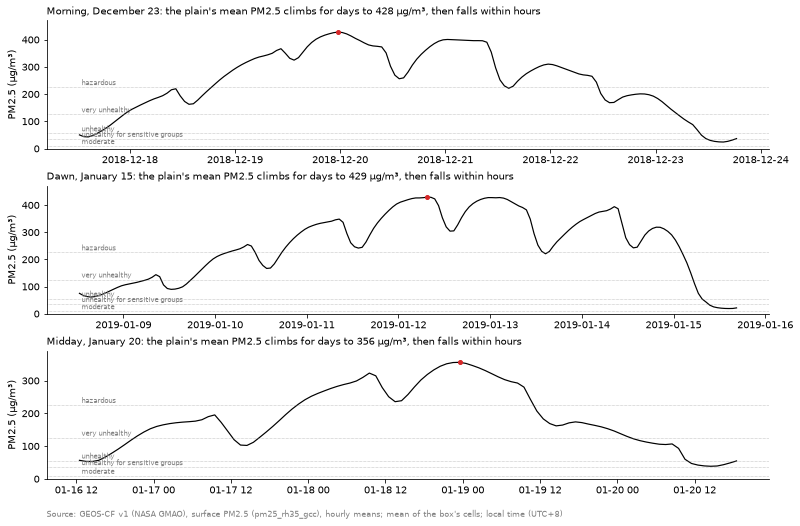

In [5]:
fig, axes = plt.subplots(len(songs), 1, figsize=(11, 2.4 * len(songs)), constrained_layout=True)
for ax, (name, local, frames) in zip(axes, songs.values()):
    mean = frames.reshape(len(local), -1).mean(axis=1)
    ax.plot(local, mean, color="k", lw=1.2)
    for value, label in EPA_BANDS:
        if value < mean.max() * 1.1:
            ax.axhline(value, color="gray", lw=0.5, ls=":")
            ax.annotate(label, (local[0], value), (2, 2), textcoords="offset points", fontsize=7, color="gray")
    worst = int(np.argmax(mean))
    ax.plot(local[worst], mean[worst], "o", ms=4, color="tab:red")
    ax.set_ylim(0, mean.max() * 1.1)
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_title(f"{name}: the plain's mean PM2.5 climbs for days to {mean[worst]:.0f} µg/m³, then falls within hours",
                 loc="left", fontsize=10)
source_note(axes[-1], CREDIT + "; mean of the box's cells; local time (UTC+8)")
plt.show()

### 4.1 On the map

Each song at three hours: its first, its worst (the box's highest mean) and its last. The front sweeps the smog south and east, out of the box.

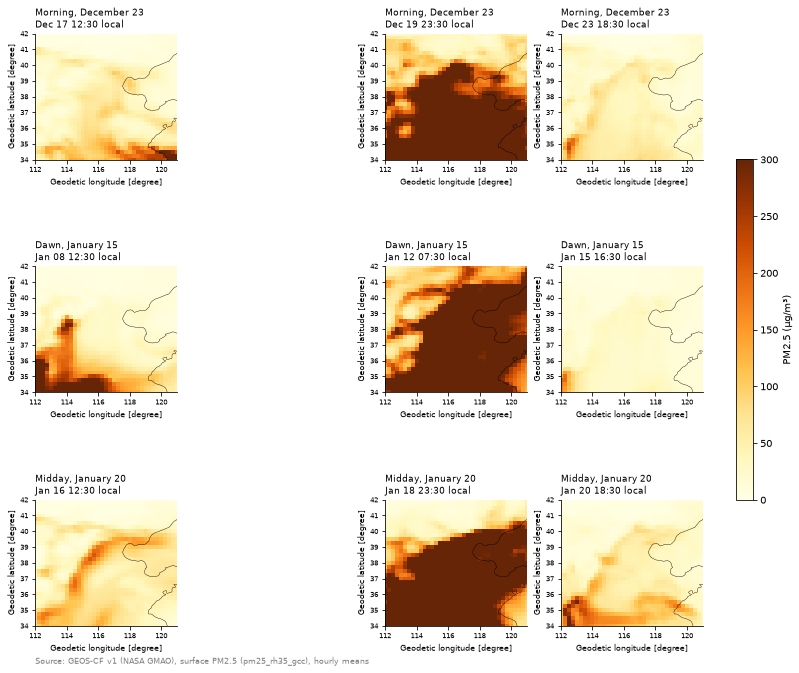

In [6]:
countries = gpd.read_file(download("natural_earth/ne_50m_admin_0_countries.zip",
                                   f"{NATURAL_EARTH_50M}/ne_50m_admin_0_countries.zip"))
fig, axes = plt.subplots(len(songs), 3, figsize=(11, 3.3 * len(songs)), constrained_layout=True)
for row, (name, local, frames) in zip(axes, songs.values()):
    worst = int(np.argmax(frames.reshape(len(local), -1).mean(axis=1)))
    for ax, h in zip(row, (0, worst, len(local) - 1)):
        mesh = ax.pcolormesh(LONS, LATS, frames[h], cmap="YlOrBr", vmin=0, vmax=300, shading="nearest")
        countries.boundary.plot(ax=ax, color="k", linewidth=0.4)
        ax.set_xlim(LONS[0], LONS[-1]); ax.set_ylim(LATS[0], LATS[-1]); ax.set_aspect("equal")
        ax.set_title(f"{name}\n{local[h]:%b %d %H:%M} local", fontsize=9, loc="left")
        ax.tick_params(labelsize=7)
fig.colorbar(mesh, ax=axes, shrink=0.5, label="PM2.5 (µg/m³)")
source_note(axes[-1, 0], CREDIT)
plt.show()

## 5. Track data

Each song becomes one CSV in `data/smog/tracks/`: a row per hour (`time`, in UTC), then each cell's PM2.5 rounded to whole µg/m³, south to north and west to east (a column per cell, named `<lat>_<lon>`). `tracks.json` gives the box and the time zone the app shows the clock in.

In [7]:
TRACKS.mkdir(parents=True, exist_ok=True)
MESSAGE = ("Though small particles typically remain in the atmosphere for only a few days, they can be transported far "
           "away from source regions by large scale weather systems.")
COLUMNS = [f"{lat:g}_{lon:g}" for lat in LATS for lon in LONS]

entries, summary = [], []
for (file, name, first, last), (_, local, frames) in zip(SONGS, songs.values()):
    i0 = hour_index(utc_of(first))
    table = pd.DataFrame(np.round(frames.reshape(len(local), -1)).astype(int), columns=COLUMNS)
    table.insert(0, "time", [f"{utc_of(t):%Y-%m-%dT%H:%MZ}" for t in local])
    table.to_csv(TRACKS / file, index=False)
    entries.append({
        "file": file,
        "title": name,
        "pages": [{"svsId": 5151, "svsUrl": "https://svs.gsfc.nasa.gov/5151/", "message": MESSAGE}],
        "note": ("Ours (from nell-v2): the North China Plain in the winter of 2018-19, a stretch from clear air through "
                 "smog building for days to a cold front sweeping it out, every hour of it."),
        "sources": [{
            "source": f"GEOS-CF v1 (NASA GMAO), aqc_tavg_1hr_g1440x721_v1, {VARIABLE}",
            "sourceUrl": "https://gmao.gsfc.nasa.gov/gmao-products/geos-cf/",
            "downloadUrl": f"{OPENDAP}.dods?{VARIABLE}[{i0}:{i0 + len(local) - 1}][0][{ROW0}:{ROW1}][{COL0}:{COL1}]",
            "version": "v1",
            "doi": "https://doi.org/10.1029/2020MS002413",
            "downloaded": "2026-11-15",
            "license": "NASA data, no restrictions on use",
            "credit": ("Keller, C. A., et al. (2021). Description of the NASA GEOS composition forecast modeling system "
                       "GEOS-CF v1.0. JAMES 13, e2020MS002413."),
            "substitute": "EIC 5151 links GEOS-CF v2, which starts on 2025-08-04; the winter of 2018-19 is only in v1.",
        }],
        "grid": {"south": float(LATS[0]), "west": float(LONS[0]), "stepDeg": GRID_DEG, "rows": ROWS, "cols": COLS},
        "timeZone": TIME_ZONE,
        "units": {"<lat>_<lon>": "µg/m³ (surface PM2.5 at 35 % relative humidity, hourly mean, the cell centred there)"},
        "timeRange": [table["time"].iloc[0], table["time"].iloc[-1]],
    })
    size = (TRACKS / file).stat().st_size
    assert size < 3e6, (file, size)
    summary.append({"song": name, "file": file, "local": f"{local[0]:%m-%d %H:%M} to {local[-1]:%m-%d %H:%M}",
                    "hours": len(local), "peak mean (µg/m³)": round(float(frames.reshape(len(local), -1).mean(axis=1).max())),
                    "KB": round(size / 1024)})
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
pd.DataFrame(summary).set_index("song")

,file,local,hours,peak mean (µg/m³),KB
song,,,,,
"Morning, December 23",smog_2018_12_23.csv,12-17 12:30 to 12-23 18:30,151,428,655
"Dawn, January 15",smog_2019_01_15.csv,01-08 12:30 to 01-15 16:30,173,429,757
"Midday, January 20",smog_2019_01_20.csv,01-16 12:30 to 01-20 18:30,103,356,440


## 6. Summary

| Item | Value |
| --- | --- |
| EIC page | [5151 Particulate Matter (PM) 2.5](https://svs.gsfc.nasa.gov/5151/) |
| EIC message | Small particles stay in the air for a few days and are carried far from their sources by the weather |
| Region and stretches (ours, from nell-v2) | The North China Plain, 34–42° N, 112–121° E; three winter stretches of 2018-19, each from clear air through days of smog to a front sweeping it out |
| Tracks | The three songs above: every hour of each stretch, every 0.25° cell of the box |
| What the app does with them | `src/features/tracks/domain/smog.js`: the fog, the turns, the pace (54 s a song); see [docs/albums/smog.md](../docs/albums/smog.md) |